### Looking at data costs

In [1]:
import databento as db
import pandas as pd
from dotenv import load_dotenv
load_dotenv()
import os
START = pd.Timestamp(2025,7,24,00,00,00)
END = pd.Timestamp(2026,7,23,00,00,00)
DATASET = "XNAS.ITCH"
SCHEMAS = ["imbalance", "tbbo", "statistics", "mbp-1"]
# SCHEMAS = ["ohlcv-1d"]
# UNIVERSE = "ALL_SYMBOLS"
with open("../top_500_universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]


client = db.Historical(os.getenv("DATABENTO_API_KEY"))
total_cost = 0
total_size = 0

for schema in SCHEMAS:
    cost = client.metadata.get_cost(
        dataset=DATASET,
        symbols=UNIVERSE,
        start=START,
        end=END,
        schema=schema
    )

    size = client.metadata.get_billable_size(
        dataset=DATASET,
        symbols=UNIVERSE,
        start=START,
        end=END,
        schema=schema
    )
    print(f"{schema} Cost: ${cost:,.2f}, Uncompressed Size: {size / 1e9:,.2f} GB")
    total_cost += cost
    total_size += size

print(f"Total Cost: ${total_cost:,.2f}, Uncompressed Size: {total_size / 1e9:,.2f} GB")

imbalance Cost: $95.31, Uncompressed Size: 7.00 GB
tbbo Cost: $0.00, Uncompressed Size: 158.29 GB
statistics Cost: $0.00, Uncompressed Size: 0.02 GB
mbp-1 Cost: $0.00, Uncompressed Size: 985.32 GB
Total Cost: $95.31, Uncompressed Size: 1,150.63 GB


## Universe Selection

In [ ]:
# from data_collection.data_adapters import DatabentoGenericAdapter
# from dotenv import load_dotenv
# from pathlib import Path
# import os
# import polars as pl
# load_dotenv()
# pl.enable_string_cache()

# CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
# adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

# print(f"CACHE_DIR: {CACHE_DIR}")

# START = "2025-01-01"
# END = "2025-06-10"
# DATASET = "XNAS.ITCH"

# day_bars = (
#     await adapter.get_data(
#         tickers="ALL_SYMBOLS",
#         start_date=START,
#         end_date=END,
#         dataset=DATASET,
#         schema="ohlcv-1d"
#     )
# )

# defs = (
#     await adapter.get_data(
#         tickers="ALL_SYMBOLS",
#         start_date=START,
#         end_date=END,
#         dataset=DATASET,
#         schema="definition"
#     )
# )

CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] Parquet cache hit: 071ad5a677ce9293c6d67d8690241537.parquet
[GenericAdapter] Parquet cache hit: dfe53a630b267abb902eaad84d85a1dd.parquet


In [ ]:
# nasdaq_stocks = (
#     defs
#     .group_by("symbol")
#     .agg(
#         pl.col("security_type").last().alias("sec_type"),
#         (pl.col("exchange") == "XNAS").all().alias("xnas_full_window"),
#         pl.col("exchange").n_unique().alias("n_exch"),
#     )
#     .filter(
#         (pl.col("sec_type") == "C") & pl.col("xnas_full_window"),
#         ~pl.col("symbol").str.contains(r"ZZT$|^Z[A-Z]YZ|^ZBZX|^ZSPC|^ZWZ")
#     )
#     .select("symbol")
#     .sort("symbol")
# )
# print(f"{nasdaq_stocks.height} common stocks listed on XNAS for the full window")
# nasdaq_stocks = nasdaq_stocks.to_series().to_list()
# nasdaq_stocks

2700 common stocks listed on XNAS for the full window


['AADI',
 'AAL',
 'AAME',
 'AAOI',
 'AAON',
 'AAPL',
 'AARD',
 'ABAT',
 'ABEO',
 'ABL',
 'ABNB',
 'ABOS',
 'ABP',
 'ABSI',
 'ABUS',
 'ABVC',
 'ABVE',
 'ACAD',
 'ACB',
 'ACCD',
 'ACDC',
 'ACET',
 'ACGL',
 'ACHC',
 'ACHV',
 'ACIC',
 'ACIU',
 'ACIW',
 'ACLS',
 'ACLX',
 'ACMR',
 'ACNB',
 'ACNT',
 'ACOG',
 'ACON',
 'ACRS',
 'ACRV',
 'ACT',
 'ACTG',
 'ACTU',
 'ACXP',
 'ADBE',
 'ADEA',
 'ADGM',
 'ADI',
 'ADIL',
 'ADMA',
 'ADN',
 'ADP',
 'ADPT',
 'ADSK',
 'ADTN',
 'ADTX',
 'ADUR',
 'ADUS',
 'ADV',
 'ADVB',
 'ADVM',
 'AEHL',
 'AEHR',
 'AEI',
 'AEIS',
 'AEMD',
 'AENT',
 'AEP',
 'AEYE',
 'AFBI',
 'AFCG',
 'AFMD',
 'AFRM',
 'AFYA',
 'AGAE',
 'AGEN',
 'AGFY',
 'AGH',
 'AGIO',
 'AGNC',
 'AGRI',
 'AGYS',
 'AHCO',
 'AIEV',
 'AIFF',
 'AIHS',
 'AIMD',
 'AIOT',
 'AIP',
 'AIRE',
 'AIRG',
 'AIRJ',
 'AIRO',
 'AIRS',
 'AIRT',
 'AISP',
 'AKAM',
 'AKBA',
 'AKRO',
 'AKYA',
 'ALAB',
 'ALBT',
 'ALCE',
 'ALCO',
 'ALDX',
 'ALEC',
 'ALGM',
 'ALGN',
 'ALGS',
 'ALGT',
 'ALHC',
 'ALKT',
 'ALLK',
 'ALLO',
 'ALLR',
 'ALM

In [ ]:
# k = 50
# top_k = (
#     day_bars
#     .select(["ts_event", "symbol", "close", "volume"])
#     .group_by(
#         by="symbol"
#     )
#     .agg(
#         (pl.col("close")*pl.col("volume")).mean().alias("ADV")
#     )
#     .rename({"by":"symbol"})
#     .filter(pl.col("symbol").is_in(nasdaq_stocks))
#     .top_k(k, by="ADV")
#     .select("symbol")
#     .to_series()
#     .to_list()
# )

# # -- Write to Unvierse File --
# with open(f"../top_{k}_universe.txt", "x") as f:
#     f.write("\n".join(top_k))

In [ ]:
# top_k

['NVDA',
 'TSLA',
 'AAPL',
 'MSFT',
 'AMZN',
 'META',
 'GOOGL',
 'AVGO',
 'PLTR',
 'MSTR',
 'GOOG',
 'NFLX',
 'AMD',
 'COST',
 'COIN',
 'APP',
 'MU',
 'SMCI',
 'QCOM',
 'TXN',
 'CRWD',
 'CSCO',
 'INTC',
 'HOOD',
 'ADBE',
 'BKNG',
 'MRVL',
 'AMAT',
 'TMUS',
 'PEP',
 'INTU',
 'ISRG',
 'LRCX',
 'CRWV',
 'DASH',
 'GILD',
 'AMGN',
 'ADI',
 'KLAC',
 'PANW',
 'SBUX',
 'CMCSA',
 'CEG',
 'HON',
 'VRTX',
 'MELI',
 'NXPI',
 'PYPL',
 'ABNB',
 'REGN']

## Random

In [23]:
import numpy as np
lower = 1
upper = 500
arr = np.arange(lower, upper + 1)

arr

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [27]:
z = (arr - lower) / (upper - lower)
z = 2 * z - 1
z

array([-1.        , -0.99599198, -0.99198397, -0.98797595, -0.98396794,
       -0.97995992, -0.9759519 , -0.97194389, -0.96793587, -0.96392786,
       -0.95991984, -0.95591182, -0.95190381, -0.94789579, -0.94388778,
       -0.93987976, -0.93587174, -0.93186373, -0.92785571, -0.9238477 ,
       -0.91983968, -0.91583166, -0.91182365, -0.90781563, -0.90380762,
       -0.8997996 , -0.89579158, -0.89178357, -0.88777555, -0.88376754,
       -0.87975952, -0.8757515 , -0.87174349, -0.86773547, -0.86372745,
       -0.85971944, -0.85571142, -0.85170341, -0.84769539, -0.84368737,
       -0.83967936, -0.83567134, -0.83166333, -0.82765531, -0.82364729,
       -0.81963928, -0.81563126, -0.81162325, -0.80761523, -0.80360721,
       -0.7995992 , -0.79559118, -0.79158317, -0.78757515, -0.78356713,
       -0.77955912, -0.7755511 , -0.77154309, -0.76753507, -0.76352705,
       -0.75951904, -0.75551102, -0.75150301, -0.74749499, -0.74348697,
       -0.73947896, -0.73547094, -0.73146293, -0.72745491, -0.72

In [1]:
with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]

In [3]:
UNIVERSE[:50]

['NVDA',
 'SPY',
 'TSLA',
 'QQQ',
 'AAPL',
 'MSFT',
 'AMZN',
 'META',
 'GOOGL',
 'AVGO',
 'AMD',
 'TLT',
 'GOOG',
 'IWM',
 'NFLX',
 'TQQQ',
 'MU',
 'COST',
 'ADBE',
 'QCOM',
 'COIN',
 'SMCI',
 'INTC',
 'SMH',
 'MSTR',
 'TXN',
 'AMAT',
 'PEP',
 'CSCO',
 'BKNG',
 'ASML',
 'LRCX',
 'TMUS',
 'HYG',
 'INTU',
 'PDD',
 'PANW',
 'CRWD',
 'MRVL',
 'CMCSA',
 'ADI',
 'AMGN',
 'LIN',
 'VOO',
 'LQD',
 'SBUX',
 'KLAC',
 'PYPL',
 'HON',
 'IVV']

## Close-auction markout

Where in the 15:50 → close window does the forecast return actually get paid? Top-49 universe,
`tbbo` mids marked off the first 15:50 imbalance print, cross-sectionally demeaned per day.

[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet


/var/folders/72/cq20lp7n6zngdk68w66r9q9r0000gn/T/ipykernel_14466/3556168325.py:90: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .join_asof(_mid, left_on="t0", right_on="ts_event", by=["symbol", "date"], strategy="backward")


[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


/var/folders/72/cq20lp7n6zngdk68w66r9q9r0000gn/T/ipykernel_14466/3556168325.py:108: UserWarning: Sortedness of columns cannot be checked when 'by' groups provided
  .join_asof(_mid, left_on="ts_q", right_on="ts_event", by=["symbol", "date"], strategy="backward")


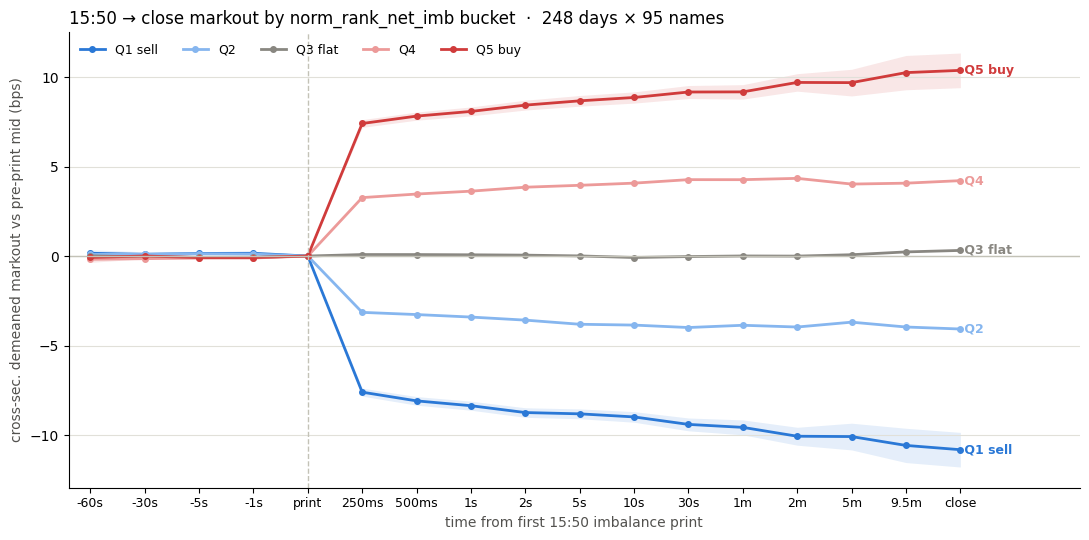

shape: (17, 3)
┌─────────┬────────────┬───────────┐
│ h       ┆ Q1 sell    ┆ Q5 buy    │
│ ---     ┆ ---        ┆ ---       │
│ f64     ┆ f64        ┆ f64       │
╞═════════╪════════════╪═══════════╡
│ -60.0   ┆ 0.156276   ┆ -0.076517 │
│ -30.0   ┆ 0.093724   ┆ 0.002521  │
│ -5.0    ┆ 0.144928   ┆ -0.083731 │
│ -1.0    ┆ 0.155513   ┆ -0.082189 │
│ 0.0     ┆ 0.0        ┆ 0.0       │
│ …       ┆ …          ┆ …         │
│ 60.0    ┆ -9.56886   ┆ 9.170366  │
│ 120.0   ┆ -10.064319 ┆ 9.697886  │
│ 300.0   ┆ -10.082754 ┆ 9.6865    │
│ 570.0   ┆ -10.577611 ┆ 10.245916 │
│ 10000.0 ┆ -10.816809 ┆ 10.372347 │
└─────────┴────────────┴───────────┘


In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from dotenv import load_dotenv

from data_collection.data_adapters import DatabentoGenericAdapter

load_dotenv()
REPO = Path.cwd().resolve().parents[0]          # notebook runs from notebook_studies/
CACHE_DIR = REPO / "data" / "dbn_cache" / "generic"
SLICE_PATH = REPO / "data" / "markout_tape_slice.parquet"   # gitignored (**/data)

BROAD = [l.strip() for l in open(REPO / "universe.txt") if l.strip()]      # cache-key set
ACTIVE = [l.strip() for l in open(REPO / "top_100_universe.txt") if l.strip()]
START, END, DATASET = "2025-06-11", "2026-06-11", "XNAS.ITCH"
DATE_FLOOR = None      # e.g. pl.date(2026, 3, 1) to prototype on a short window

adapter = DatabentoGenericAdapter(os.getenv("DATABENTO_API_KEY"), CACHE_DIR)
_floor = (pl.col("ts_event").dt.date() >= DATE_FLOOR) if DATE_FLOOR is not None else pl.lit(True)

# ---- 1. tbbo tape around the cross (one-time streaming extract; ~105GB scan) ----
if not SLICE_PATH.exists():
    (
        adapter.scan_data(BROAD, START, END, DATASET, "tbbo")
        .select("ts_event", "symbol", "price", "size", "bid_px_00", "ask_px_00")
        .filter(
            pl.col("symbol").is_in(ACTIVE), _floor,
            pl.col("ts_event").dt.time().is_between(pl.time(19, 30), pl.time(21, 10)),  # UTC pre-cut, DST-safe
        )
        .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"))
        .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 45), pl.time(16, 0, 30)))
        .with_columns(
            pl.col("ts_event").dt.date().alias("date"),
            ((pl.col("bid_px_00") + pl.col("ask_px_00")) / 2).alias("mid"),
        )
        .filter(pl.col("mid").is_not_null(), pl.col("mid") > 0)
        .select("date", "symbol", "ts_event", "mid", "price", "size")
        .sort("symbol", "date", "ts_event")
        .sink_parquet(SLICE_PATH)
    )
tape = pl.read_parquet(SLICE_PATH).sort("symbol", "date", "ts_event")

# ---- 2. first close-imbalance print of the day -> t0 + norm_rank_net_imb ----
_sign = pl.when(pl.col("side") == "B").then(1).when(pl.col("side") == "A").then(-1).otherwise(0)
_r = pl.col("net_signed_imb").rank().over("date")
imb = (
    adapter.scan_data(BROAD, START, END, DATASET, "imbalance")
    .select("ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price")
    .filter(pl.col("symbol").is_in(ACTIVE), _floor)
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15, 50), pl.time(15, 50, 5)))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by("date", "symbol")
    .agg(
        pl.col("ts_event").first().alias("t0"),                 # first NOII print
        pl.col("side").first(), pl.col("total_imbalance_qty").first(),
        pl.col("paired_qty").first(), pl.col("ref_price").first(),
    )
    .collect(engine="streaming")
    # NB: qty is UInt32 -- multiply by ref_price FIRST or -1 * u32 underflows to null.
    .with_columns(
        (_sign * (pl.col("total_imbalance_qty") * pl.col("ref_price"))).alias("signed_dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
    )
    .with_columns(
        pl.when(pl.col("paired_dollars") != 0)
        .then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
        .otherwise(0.0).alias("net_signed_imb")
    )
    .with_columns(   # live.features._norm_rank_expr, verbatim
        ((_r - _r.min().over("date")) / (_r.max().over("date") - _r.min().over("date")) * 2 - 1)
        .alias("norm_rank_net_imb")
    )
    .drop_nulls("norm_rank_net_imb")
)

# ---- 3. markout panel: mid at t0 + h, plus the official close cross ----
OFFSETS = [-60.0, -30.0, -5.0, -1.0, 0.0, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 30.0,
           60.0, 120.0, 300.0, 570.0]
LABELS = {-60.0: "-60s", -30.0: "-30s", -5.0: "-5s", -1.0: "-1s", 0.0: "print", 0.25: "250ms",
          0.5: "500ms", 1.0: "1s", 2.0: "2s", 5.0: "5s", 10.0: "10s", 30.0: "30s",
          60.0: "1m", 120.0: "2m", 300.0: "5m", 570.0: "9.5m", 1e4: "close"}

_mid = tape.select("date", "symbol", "ts_event", "mid")
p0 = (
    imb.select("date", "symbol", "t0").sort("symbol", "date", "t0")
    .join_asof(_mid, left_on="t0", right_on="ts_event", by=["symbol", "date"], strategy="backward")
    .rename({"mid": "p0"}).select("date", "symbol", "p0")
)
auction = (
    adapter.scan_data(BROAD, START, END, DATASET, "statistics")
    .select("ts_event", "stat_type", "symbol", "price")
    .filter(pl.col("stat_type") == 11, pl.col("symbol").is_in(ACTIVE), _floor)   # 11 = closing price
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by("date", "symbol").agg(pl.col("price").last().alias("mid_h"))
    .collect(engine="streaming")
    .with_columns(pl.lit(1e4).alias("h"))
)
panel = (
    imb.select("date", "symbol", "t0", "net_signed_imb", "norm_rank_net_imb", "paired_dollars")
    .join(pl.DataFrame({"h": OFFSETS}), how="cross")
    .with_columns((pl.col("t0") + pl.duration(nanoseconds=(pl.col("h") * 1e9).cast(pl.Int64))).alias("ts_q"))
    .sort("symbol", "date", "ts_q")
    .join_asof(_mid, left_on="ts_q", right_on="ts_event", by=["symbol", "date"], strategy="backward")
    .rename({"mid": "mid_h"})
    # how stale is the quote we marked against? tbbo only ticks on trades.
    .with_columns((pl.col("ts_q") - pl.col("ts_event")).dt.total_milliseconds().alias("stale_ms"))
    .select("date", "symbol", "t0", "net_signed_imb", "norm_rank_net_imb", "paired_dollars",
            "h", "mid_h", "stale_ms")
    .vstack(
        imb.select("date", "symbol", "t0", "net_signed_imb", "norm_rank_net_imb", "paired_dollars")
        .join(auction, on=["date", "symbol"], how="inner")
        .with_columns(pl.lit(None, dtype=pl.Int64).alias("stale_ms"))
        .select("date", "symbol", "t0", "net_signed_imb", "norm_rank_net_imb", "paired_dollars",
                "h", "mid_h", "stale_ms")
    )
    .join(p0, on=["date", "symbol"], how="left")
    .drop_nulls(["p0", "mid_h"])
    .with_columns((1e4 * (pl.col("mid_h") - pl.col("p0")) / pl.col("p0")).alias("mk_bps"))
    .with_columns((pl.col("mk_bps") - pl.col("mk_bps").mean().over("date", "h")).alias("mk_xm"))
    .with_columns(
        pl.col("norm_rank_net_imb")
        .cut([-0.6, -0.2, 0.2, 0.6], labels=["Q1 sell", "Q2", "Q3 flat", "Q4", "Q5 buy"])
        .alias("bucket")
    )
)

# ---- 4. plot ----
curve = (
    panel.group_by("bucket", "h")
    .agg(pl.col("mk_xm").mean().alias("m"), pl.col("mk_xm").std().alias("s"), pl.len().alias("n"))
    .with_columns((2 * pl.col("s") / pl.col("n").sqrt()).alias("se2"))
    .sort("h")
)
xs = OFFSETS + [1e4]
COLORS = {"Q1 sell": "#2a78d6", "Q2": "#86b6ef", "Q3 flat": "#898781", "Q4": "#ec9a99", "Q5 buy": "#d03b3b"}

fig, ax = plt.subplots(figsize=(11, 5.5))
for b, c in COLORS.items():
    d = curve.filter(pl.col("bucket") == b).sort("h")
    y = d["m"].to_numpy()
    x = np.arange(len(d))
    if b in ("Q1 sell", "Q5 buy"):
        ax.fill_between(x, y - d["se2"].to_numpy(), y + d["se2"].to_numpy(), color=c, alpha=0.12, lw=0)
    ax.plot(x, y, color=c, lw=2, marker="o", ms=4, label=b)
    ax.annotate(f" {b}", (x[-1], y[-1]), color=c, fontsize=9, va="center", fontweight="bold")

ax.axhline(0, color="#c3c2b7", lw=1)
ax.axvline(OFFSETS.index(0.0), color="#c3c2b7", lw=1, ls="--")
ax.set_xticks(np.arange(len(xs)), [LABELS[h] for h in xs], fontsize=9)
ax.set_xlim(-0.4, len(xs) + 1.2)
ax.set_xlabel("time from first 15:50 imbalance print", fontsize=10, color="#52514e")
ax.set_ylabel("cross-sec. demeaned markout vs pre-print mid (bps)", fontsize=10, color="#52514e")
ax.set_title(f"15:50 → close markout by norm_rank_net_imb bucket  ·  "
             f"{panel['date'].n_unique()} days × {panel['symbol'].n_unique()} names",
             fontsize=12, loc="left")
ax.legend(frameon=False, fontsize=9, ncols=5, loc="upper left")
ax.grid(axis="y", color="#e1e0d9", lw=0.8)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
fig.tight_layout()
plt.show()

print(curve.filter(pl.col("bucket").is_in(["Q1 sell", "Q5 buy"]))
      .pivot(on="bucket", index="h", values="m").sort("h"))

In [2]:
# How much of the 15:50 -> close move is already done at 250ms / 500ms / 1s / 10s / 30s
HZ = [0.25, 0.5, 1.0, 10.0, 30.0, 1e4]        # 1e4 == the official close cross
CLOSE_H, CLOSE_LBL = 1e4, LABELS[1e4]
HZ_ORDER = [LABELS[h] for h in HZ]

LIQ = pl.Enum(["L1 thin", "L2", "L3 deep"])

# ---- ADV from the daily-bar cache (the schema covariance.ipynb reads) ----
# close*volume, EWMA(span=10) shifted 1 day -- the forecasting.ipynb recipe, so these
# buckets use the same ADV definition the alpha model trains against. This slot spans
# 2023-09-16 .. 2026-06-11, giving ~21 months of warm-up before the study window, and
# it is per-(date, symbol): a name can migrate between terciles over the year.
_pct = (pl.col("ADV").rank().over("date") - 1) / (pl.col("ADV").count().over("date") - 1)
adv = (
    adapter.scan_data("ALL_SYMBOLS", "2023-09-16", "2026-06-11", DATASET, "ohlcv-1d")
    .select("ts_event", "symbol", "close", "volume")
    .filter(pl.col("symbol").is_in(ACTIVE))
    .select(
        pl.col("ts_event").dt.date().alias("date"),   # daily bars stamp 00:00 UTC on the session date
        "symbol",
        (pl.col("close") * pl.col("volume")).alias("day_volume"),
    )
    .sort("date")
    .with_columns(
        pl.col("day_volume").ewm_mean(span=10, adjust=True)
        .shift(1).over("symbol", order_by="date").alias("ADV")   # shift => causal
    )
    .drop("day_volume")
    .collect(engine="streaming")
    .drop_nulls("ADV")
    .with_columns(
        pl.when(_pct < 1 / 3).then(pl.lit("L1 thin"))
        .when(_pct < 2 / 3).then(pl.lit("L2"))
        .otherwise(pl.lit("L3 deep")).cast(LIQ).alias("liq")
    )
)
# symbol-level summary for the per-symbol tables: typical ADV + modal bucket
adv_sym = (
    adv.join(panel.select("date").unique(), on="date", how="semi")
    .group_by("symbol")
    .agg(pl.col("ADV").median().alias("ADV"), pl.col("liq").mode().first().alias("liq"))
)

# alpha-aligned markout: flip the sell side so every bucket is signed the same way
mk = (
    panel.filter(pl.col("h").is_in(HZ))
    .join(adv, on=["date", "symbol"], how="left")
    .with_columns(
        (pl.col("norm_rank_net_imb").sign() * pl.col("mk_xm")).alias("aligned_bps"),
        pl.col("h").replace_strict(LABELS, default=None).cast(pl.Enum(HZ_ORDER)).alias("hz"),
    )
    .with_columns((pl.col("aligned_bps") > 0).alias("hit"))
)


def describe(frame: pl.DataFrame, by: list[str]) -> pl.DataFrame:
    """Per-horizon descriptives + how much of the close move is already realised.

    ``share_of_close`` is a ratio of two noisy means, so it is only reported
    where the denominator (the close move for that group) is itself
    significant (|t| >= 2) -- otherwise it is nulled rather than printed as a
    spurious -227x. ``abs_share`` is the sign-free companion: mean |markout| at
    h over mean |markout| at the close, whose denominator is always positive.

    The two are NOT comparable. ``share_of_close`` is a ratio of drifts and
    answers "how much of the FORECAST is paid by h". ``abs_share`` is a ratio
    of move magnitudes, dominated by diffusion, and sits near 0.25 even for a
    name with no alpha at all -- read it as risk accumulation, not signal.
    """
    g = (
        frame.group_by(by + ["hz"])
        .agg(
            pl.len().alias("n"),
            pl.col("aligned_bps").mean().alias("mean_bps"),
            pl.col("aligned_bps").median().alias("med_bps"),
            pl.col("aligned_bps").std().alias("sd_bps"),
            pl.col("hit").mean().alias("hit_rate"),
            pl.col("mk_xm").abs().mean().alias("abs_bps"),
            pl.col("stale_ms").median().alias("stale_ms_med"),
        )
        .with_columns((pl.col("mean_bps") / (pl.col("sd_bps") / pl.col("n").sqrt())).alias("t"))
    )
    ref = g.filter(pl.col("hz") == CLOSE_LBL).select(
        by + [pl.col("mean_bps").alias("close_bps"), pl.col("t").alias("close_t"),
              pl.col("abs_bps").alias("_abs_close")]
    )
    return (
        g.join(ref, on=by, how="left")
        .with_columns(
            pl.when(pl.col("close_t").abs() >= 2)
            .then(pl.col("mean_bps") / pl.col("close_bps"))
            .otherwise(None).alias("share_of_close"),
            (pl.col("abs_bps") / pl.col("_abs_close")).alias("abs_share"),
        )
        .sort(by + ["hz"])
        .with_columns(
            (pl.col("share_of_close") - pl.col("share_of_close").shift(1).over(by)).alias("incr_share")
        )
        .select(by + ["hz", "n", "mean_bps", "med_bps", "t", "hit_rate", "share_of_close",
                      "incr_share", "abs_bps", "abs_share", "close_bps", "close_t", "stale_ms_med"])
    )


def matrix(frame: pl.DataFrame, by: str, value: str) -> pl.DataFrame:
    return (describe(frame, [by]).pivot(on="hz", index=by, values=value)
            .select([by] + HZ_ORDER))


def per_symbol(stats: pl.DataFrame, value: str) -> pl.DataFrame:
    """Per-symbol horizon pivot of `value`, ADV-sorted, with the close denominator."""
    return (
        stats.pivot(on="hz", index="symbol", values=value)
        .join(stats.filter(pl.col("hz") == CLOSE_LBL).select("symbol", "close_bps", "close_t"),
              on="symbol", how="left")
        .join(adv_sym, on="symbol", how="left")
        .sort("ADV", descending=True)
        .with_columns((pl.col("ADV") / 1e9).round(2).alias("ADV_$bn"))   # median over the window
        .select(["symbol", "ADV_$bn", "liq"] + HZ_ORDER + ["close_bps", "close_t"])
    )


with pl.Config(tbl_rows=80, tbl_cols=25, float_precision=3, tbl_width_chars=250):
    print("== A. overall: when does the forecast return actually happen ==")
    print(describe(mk.with_columns(pl.lit("all").alias("g")), ["g"]).drop("g"))

    print("\n== B. by feature bucket (norm_rank_net_imb) ==")
    print(describe(mk, ["bucket"]))
    print("\n   share of the SIGNED close move realised by h (null = close move not significant)")
    print(matrix(mk, "bucket", "share_of_close"))
    print("\n   share of the ABSOLUTE close move realised by h")
    print(matrix(mk, "bucket", "abs_share"))

    print("\n== C. by liquidity bucket (per-day ADV terciles) ==")
    print(describe(mk, ["liq"]))
    print("\n   signed share / absolute share of the close move realised by h")
    print(matrix(mk, "liq", "share_of_close"))
    print(matrix(mk, "liq", "abs_share"))

    print("\n== D. feature x liquidity ==")
    fx = describe(mk, ["liq", "bucket"])
    for h in [0.25, 1.0, 30.0]:
        print(f"\n   share of signed close move realised at {LABELS[h]}")
        print(fx.filter(pl.col("hz") == LABELS[h]).pivot(on="bucket", index="liq", values="share_of_close"))
    print("\n   close move itself (bps, aligned) by cell -- the denominator above")
    print(fx.filter(pl.col("hz") == CLOSE_LBL).pivot(on="bucket", index="liq", values="mean_bps"))

    per_sym = describe(mk, ["symbol"])

    print("\n== E. per symbol: share of the SIGNED close move realised (sorted by ADV) ==")
    print("      alpha-timing view: fraction of that name's forecastable move paid by h.")
    print("      null = that name's own close move is not significant (|close_t| < 2)")
    print(per_symbol(per_sym, "share_of_close"))

    print("\n== E2. per symbol: share of the ABSOLUTE close move realised ==")
    print("      risk view: fraction of that name's typical move size. Sits near 0.25")
    print("      regardless of alpha -- it tracks diffusion, so do not read it as signal.")
    print(per_symbol(per_sym, "abs_share"))

    print("\n== F. daily cross-sectional IC of norm_rank_net_imb vs markout ==")
    print(
        mk.group_by("hz", "date")
        .agg(pl.corr("norm_rank_net_imb", "mk_xm", method="spearman").alias("ic"))
        .group_by("hz")
        .agg(pl.col("ic").mean().alias("ic_mean"), pl.col("ic").std().alias("ic_sd"),
             pl.len().alias("days"), (pl.col("ic") > 0).mean().alias("ic_pos_frac"))
        .with_columns((pl.col("ic_mean") / pl.col("ic_sd") * pl.col("days").sqrt()).alias("t"))
        .sort("hz")
    )

    print("\n== G. quote staleness -- tbbo only ticks on trades, so a sub-second")
    print("      markout in a thin name may be measured against a pre-print quote ==")
    print(
        mk.filter(pl.col("h") < CLOSE_H)
        .group_by("hz", "liq")
        .agg(pl.col("stale_ms").median().alias("stale_ms_med"),
             pl.col("stale_ms").quantile(0.9).alias("stale_ms_p90"),
             (pl.col("stale_ms") > pl.col("h") * 1000).mean().alias("frac_quote_predates_print"))
        .sort("hz", "liq")
    )

[GenericAdapter] scan_parquet: a149a71f2586f19142cfbf128a5bf86f.parquet
== A. overall: when does the forecast return actually happen ==
shape: (6, 13)
┌───────┬───────┬──────────┬─────────┬─────────┬──────────┬────────────────┬────────────┬─────────┬───────────┬───────────┬─────────┬──────────────┐
│ hz    ┆ n     ┆ mean_bps ┆ med_bps ┆ t       ┆ hit_rate ┆ share_of_close ┆ incr_share ┆ abs_bps ┆ abs_share ┆ close_bps ┆ close_t ┆ stale_ms_med │
│ ---   ┆ ---   ┆ ---      ┆ ---     ┆ ---     ┆ ---      ┆ ---            ┆ ---        ┆ ---     ┆ ---       ┆ ---       ┆ ---     ┆ ---          │
│ enum  ┆ u64   ┆ f64      ┆ f64     ┆ f64     ┆ f64      ┆ f64            ┆ f64        ┆ f64     ┆ f64       ┆ f64       ┆ f64     ┆ f64          │
╞═══════╪═══════╪══════════╪═════════╪═════════╪══════════╪════════════════╪════════════╪═════════╪═══════════╪═══════════╪═════════╪══════════════╡
│ 250ms ┆ 23560 ┆ 4.429    ┆ 2.952   ┆ 105.105 ┆ 0.808    ┆ 0.716          ┆ null       ┆ 5.120   ┆ 0.23